## Importance analysis with SHAP

<i> Classification

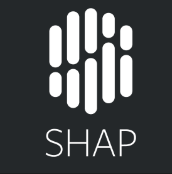


<i>

<br>

This notebook shows a basic analysis using feature importances (Shapley values.)

### <i> Imports

In [1]:
# pip install catboost
import shap
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix
from sklearn.metrics import r2_score, mean_squared_error
from catboost import CatBoostRegressor
from sklearn import metrics

c:\Users\tuomas.valtanen\dataeng_advda2026_lectures\DataEngineering_AdvDA_2026\.venv\Lib\site-packages\xgboost\compat.py:105: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


### <i> Loading

In [2]:
# Load the dataframe
df = pd.read_csv("../../diabetes.csv")
df

,pregnant,glucose,pressure,triceps,insulin,mass,pedigree,age,diabetes
0,1,89,66,23,94,28.1,0.167,21,neg
1,0,137,40,35,168,43.1,2.288,33,pos
2,3,78,50,32,88,31.0,0.248,26,pos
3,2,197,70,45,543,30.5,0.158,53,pos
4,1,189,60,23,846,30.1,0.398,59,pos
...,...,...,...,...,...,...,...,...,...
387,0,181,88,44,510,43.3,0.222,26,pos
388,1,128,88,39,110,36.5,1.057,37,pos
389,2,88,58,26,16,28.4,0.766,22,neg
390,10,101,76,48,180,32.9,0.171,63,neg


### <i> Numeric Encoding


In [3]:
from sklearn.preprocessing import LabelEncoder

# If you have a binary datatype column, this will convert it into numbers.
variables = ['diabetes']

encoder = LabelEncoder()
df[variables] = df[variables].apply(encoder.fit_transform)

 # This will convert `Yes` and `No` into `0`and `1` 

--- 

## Model training and Shap importance analysis

In [4]:
from catboost import CatBoostClassifier

# Split features and target.
X = df.drop(columns=["diabetes"])
y = df["diabetes"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)


model = CatBoostClassifier(
    iterations=50,
    loss_function="Logloss",
    eval_metric="AUC",
    verbose=0,
    random_seed=42
)

model.fit(X_train, y_train)

# Predictions
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

print("Model trained.")


Model trained.


In [5]:
from sklearn import metrics
import numpy as np

# Metrics
accuracy = metrics.accuracy_score(y_test, y_pred)
precision = metrics.precision_score(y_test, y_pred)
recall = metrics.recall_score(y_test, y_pred)
f1 = metrics.f1_score(y_test, y_pred)
roc_auc = metrics.roc_auc_score(y_test, y_prob)

# Confusion matrix
cm = metrics.confusion_matrix(y_test, y_pred)

# Classification report
report = metrics.classification_report(y_test, y_pred)

print("--------------------------")
print("CLASSIFICATION METRICS")
print("--------------------------")
print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-score:  {f1:.4f}")
print(f"ROC-AUC:   {roc_auc:.4f}")

print("\nClassification Report:")
print(report)

--------------------------
CLASSIFICATION METRICS
--------------------------
Accuracy:  0.8101
Precision: 0.7200
Recall:    0.6923
F1-score:  0.7059
ROC-AUC:   0.8723

Classification Report:
              precision    recall  f1-score   support

           0       0.85      0.87      0.86        53
           1       0.72      0.69      0.71        26

    accuracy                           0.81        79
   macro avg       0.79      0.78      0.78        79
weighted avg       0.81      0.81      0.81        79



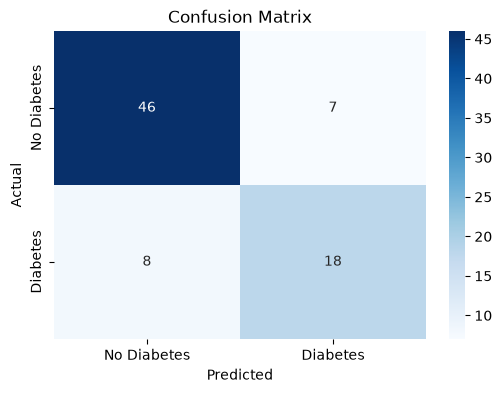

In [6]:
# Generate confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Plot
plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Diabetes", "Diabetes"],
    yticklabels=["No Diabetes", "Diabetes"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

---

### <i> Retrieving shap values

In [7]:
# Generate SHAP values
explainer = shap.TreeExplainer(model)
shap_values = explainer(X_test)
print("Shap values created")

Shap values created


### <i> Bar plot

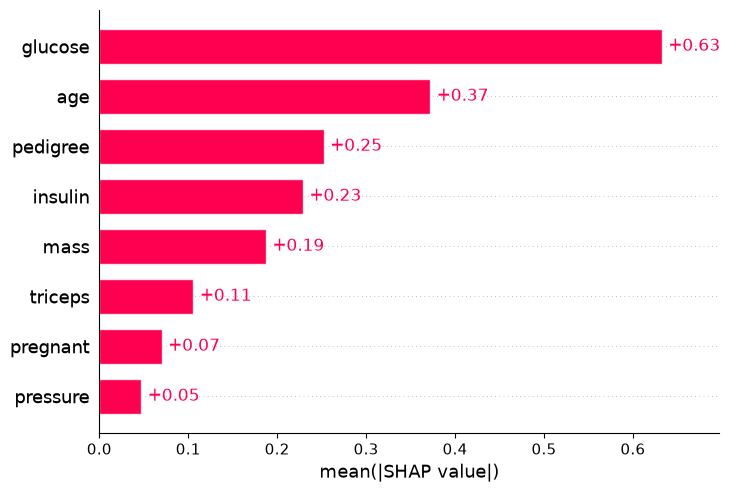

In [8]:
shap.plots.bar(shap_values)

### <i> Beeswarm plot

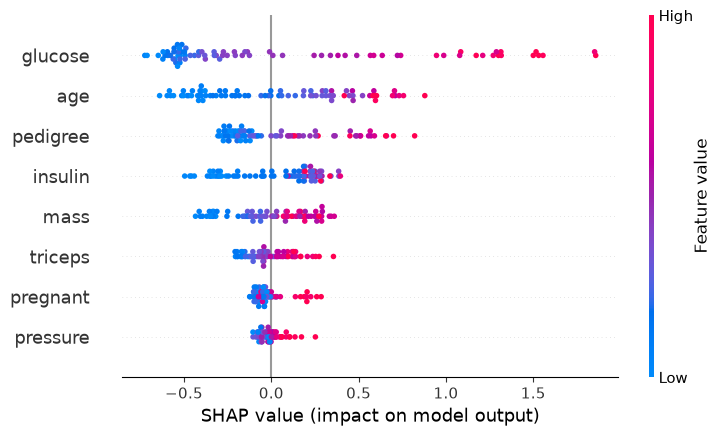

In [9]:
shap.plots.beeswarm(shap_values)

<div style="border: 3px dashed white; padding: 10px; box-sizing: border-box;">

<h3>Observations</h3>

* Very linear (color is gradient) features all throughout, just quite a bit of variation.

* `glucose` and `age` appear to be the most important predictors to `CatBoostClassifier`

* `pregnant` and `pressure` are the lowest values in important. But are they truly useful?

</div>

### <i> Cohort bar plot



<i> Taken from [SHAP documentation](https://shap.readthedocs.io/en/latest/example_notebooks/api_examples/plots/bar.html)

This is a useful visual for classification!


In [10]:
# Create cohorts based on actual diabetes labels
cohorts = []

for value in y_test:
    if value == 1:
        cohorts.append("Diabetic")
    else:
        cohorts.append("Non-diabetic")

# Group SHAP values into cohorts
cohort_values = shap_values.cohorts(cohorts)

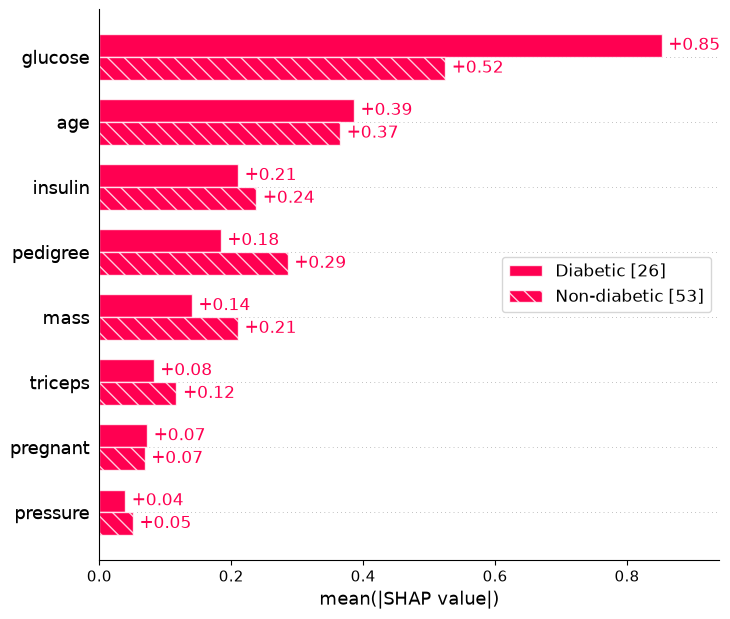

In [11]:
shap.plots.bar(cohort_values.abs.mean(0))

<div style="border: 3px dashed white; padding: 10px; box-sizing: border-box;">

<i>

<h3>Observations</h3>


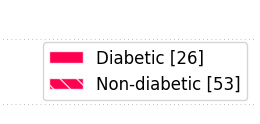

We can see in the test sample that Diabetes is a little under-represented. 

We can also see that glucose is somehow less important for non-diabetic classification. 

</div>

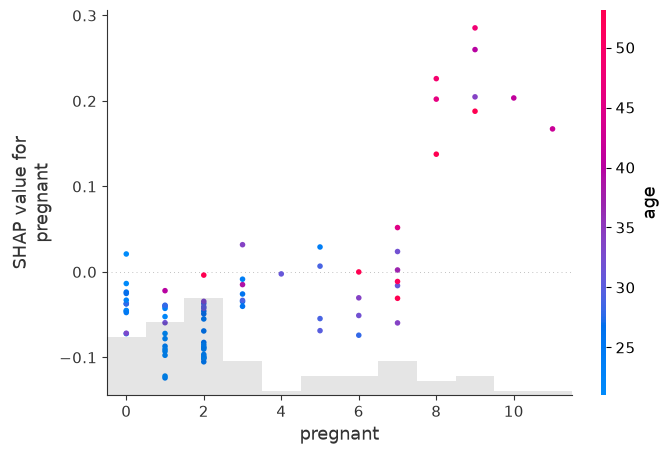

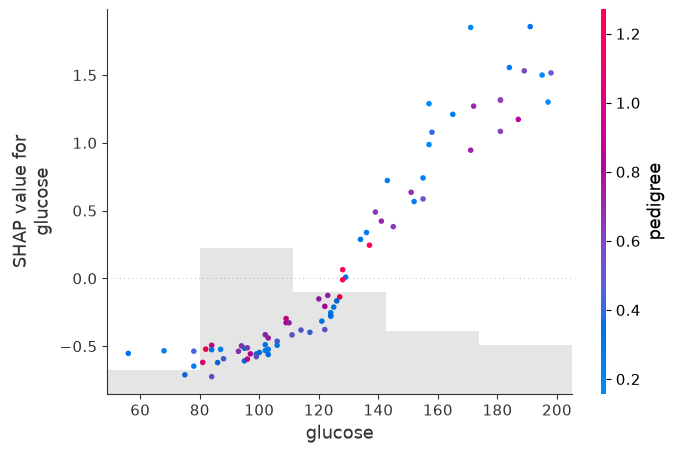

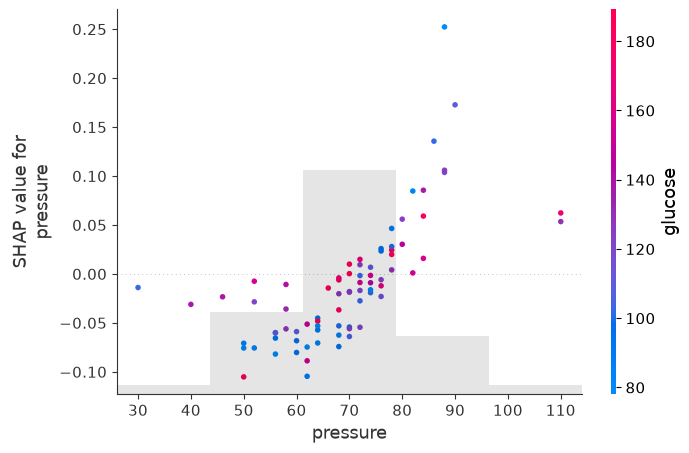

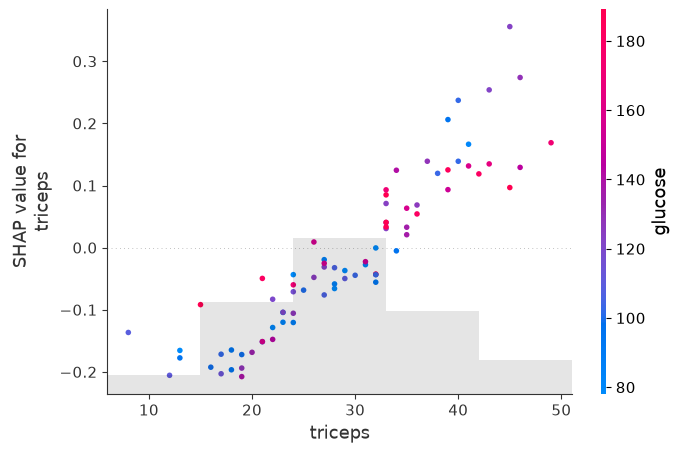

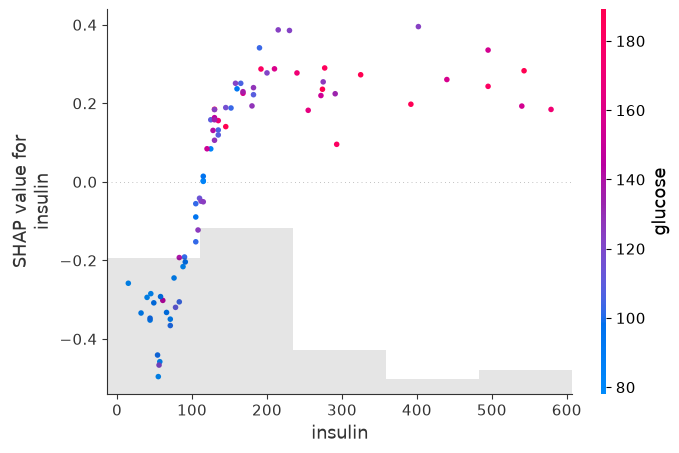

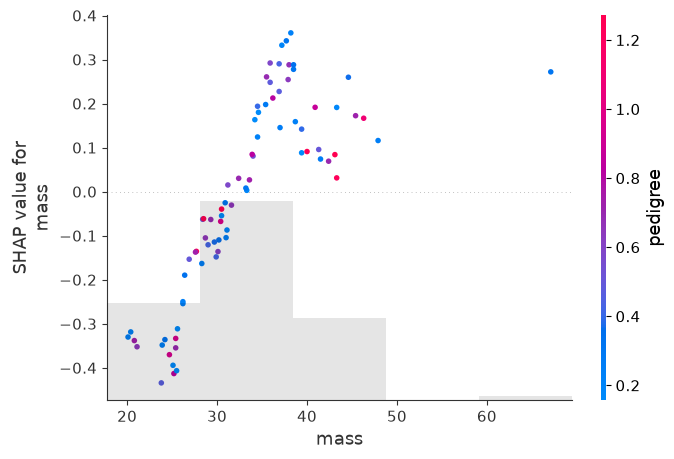

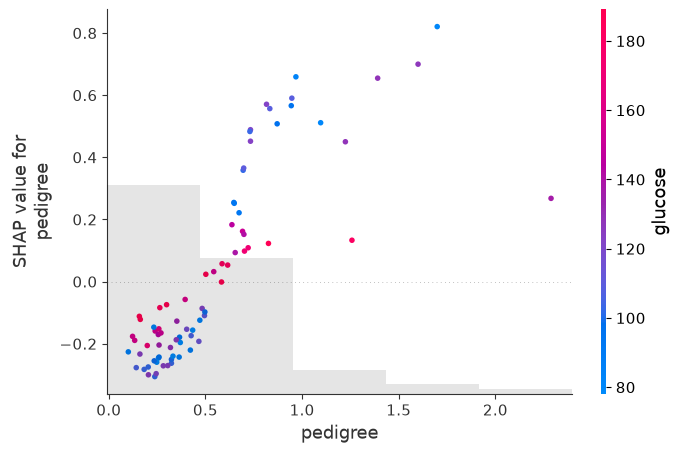

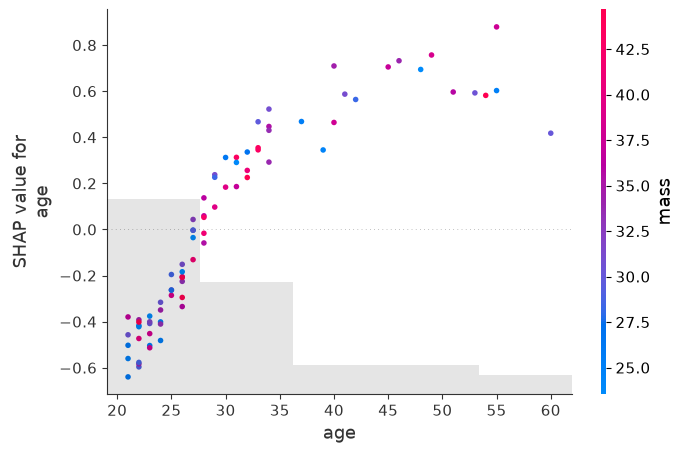

In [12]:
features = X.columns

for feature in features:

    shap.plots.scatter(
        shap_values[:, feature],
        color=shap_values,
        show=True
    )

<div style="border: 3px dashed white; padding: 10px; box-sizing: border-box;">

<i>

<h3> Insights </h3>


* Looks like there is a lot of scattered dependency, which is a good sign (If any of these are too similar, we might consider a VIF test) 

</div>



### <i> 

---

### <i> Isolating cases with SHAP

Below you'll find a very simple way to isolate cases with `SHAP` so you can inspect them more carefully.

In [13]:
# Get the prediction error.
residuals = y_test - y_pred

# Create a copy of the test dataframe
predictions_df = X_test.copy()

# Add actual and predicted values
predictions_df["Actual"] = y_test
predictions_df["Predicted"] = y_pred

# Add residuals
predictions_df["Residual"] = residuals

# Sort by the worst predictions
worst_predictions = predictions_df.sort_values("Residual", ascending=False)
worst_predictions

,pregnant,glucose,pressure,triceps,insulin,mass,pedigree,age,Actual,Predicted,Residual
60,1,117,88,24,145,34.5,0.403,40,1,0,1
363,2,93,64,32,160,38.0,0.674,23,1,0,1
337,2,155,52,27,540,38.7,0.240,25,1,0,1
2,3,78,50,32,88,31.0,0.248,26,1,0,1
152,0,128,68,19,180,30.5,1.391,25,1,0,1
...,...,...,...,...,...,...,...,...,...,...,...
125,3,191,68,15,130,30.9,0.299,34,0,1,-1
172,8,126,88,36,108,38.5,0.349,49,0,1,-1
143,6,151,62,31,120,35.5,0.692,28,0,1,-1
187,2,122,52,43,158,36.2,0.816,28,0,1,-1


<i> Use this to translate the worst_predictions index to the shapley_values index: 

In [14]:
# Find the index position in X_test from worst_predictions 
row_position = X_test.index.get_loc(60)
print(f"The shap_value index is: {row_position}")

The shap_value index is: 4


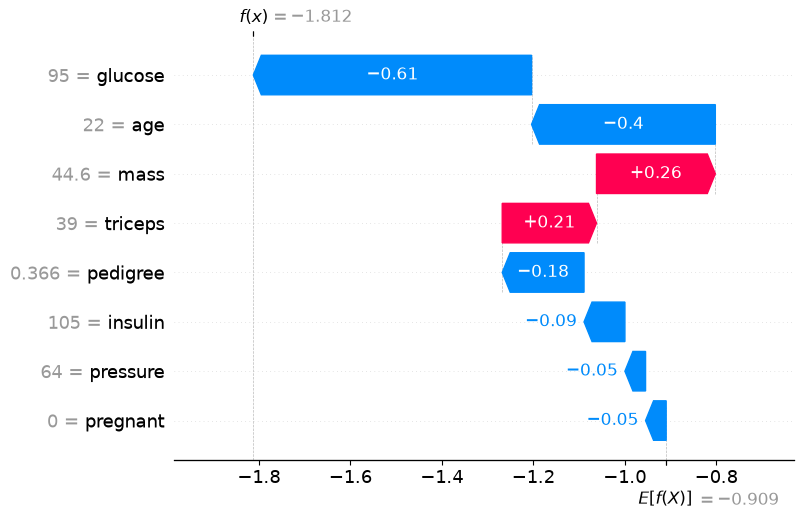

In [15]:
# Feel free to experiment!
shap.plots.waterfall(shap_values[60])

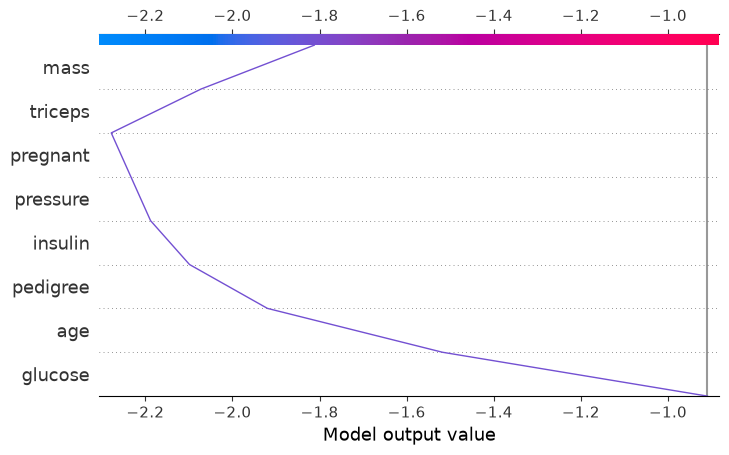

In [16]:
# Decision plot
shap.decision_plot(
    shap_values.base_values[60],
    shap_values.values[60],
    feature_names=X_test.columns.tolist(),
    feature_order="hclust",
    show=True
)

---

## <i> Minor Optimizations

In [17]:
df

,pregnant,glucose,pressure,triceps,insulin,mass,pedigree,age,diabetes
0,1,89,66,23,94,28.1,0.167,21,0
1,0,137,40,35,168,43.1,2.288,33,1
2,3,78,50,32,88,31.0,0.248,26,1
3,2,197,70,45,543,30.5,0.158,53,1
4,1,189,60,23,846,30.1,0.398,59,1
...,...,...,...,...,...,...,...,...,...
387,0,181,88,44,510,43.3,0.222,26,1
388,1,128,88,39,110,36.5,1.057,37,1
389,2,88,58,26,16,28.4,0.766,22,0
390,10,101,76,48,180,32.9,0.171,63,0


### <i> Interaction Features

Let's add an interaction feature here to see if it helps.

In [18]:
# Interaction features
df["glucose_insulin"] = df["glucose"] * df["insulin"]

### <i> LOF 

In [19]:
from sklearn.neighbors import LocalOutlierFactor

# Create LOF model.
lof = LocalOutlierFactor(
    n_neighbors=20,
    contamination=0.10
)

# Identify outliers.
outliers = lof.fit_predict(X)

# Add results to dataframe.
df["outlier"] = outliers

# -1 = Outlier
#  1 = Inlier

df = df[df["outlier"] == 1]

---

## <i> More optimized dataset

### <i> Retraining

In [20]:
from catboost import CatBoostClassifier

# Split features and target.
X = df.drop(columns=["diabetes", "outlier"])
y = df["diabetes"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)



model = CatBoostClassifier(
    iterations=100,
    loss_function="Logloss",
    eval_metric="AUC",
    verbose=0,
    random_seed=42
)

model.fit(X_train, y_train)

# Predictions
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

print("Model trained.")

Model trained.


### <i> Metrics

In [21]:
from sklearn import metrics
import numpy as np

# Metrics
accuracy = metrics.accuracy_score(y_test, y_pred)
precision = metrics.precision_score(y_test, y_pred)
recall = metrics.recall_score(y_test, y_pred)
f1 = metrics.f1_score(y_test, y_pred)
roc_auc = metrics.roc_auc_score(y_test, y_prob)

# Confusion matrix
cm = metrics.confusion_matrix(y_test, y_pred)

# Classification report
report = metrics.classification_report(y_test, y_pred)

print("--------------------------")
print("CLASSIFICATION METRICS")
print("--------------------------")
print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-score:  {f1:.4f}")
print(f"ROC-AUC:   {roc_auc:.4f}")

print("\nClassification Report:")
print(report)

--------------------------
CLASSIFICATION METRICS
--------------------------
Accuracy:  0.8310
Precision: 0.8333
Recall:    0.6250
F1-score:  0.7143
ROC-AUC:   0.8537

Classification Report:
              precision    recall  f1-score   support

           0       0.83      0.94      0.88        47
           1       0.83      0.62      0.71        24

    accuracy                           0.83        71
   macro avg       0.83      0.78      0.80        71
weighted avg       0.83      0.83      0.82        71



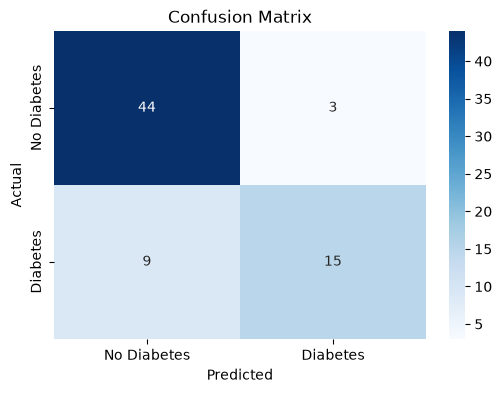

In [22]:
# Generate confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Plot
plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Diabetes", "Diabetes"],
    yticklabels=["No Diabetes", "Diabetes"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

### <i> Shap values

In [23]:
# Generate SHAP values
explainer = shap.TreeExplainer(model)
shap_values = explainer(X_test)
print("Shap values created")

Shap values created


In [24]:
# Create cohorts based on actual diabetes labels
cohorts = []

for value in y_test:
    if value == 1:
        cohorts.append("Diabetic")
    else:
        cohorts.append("Non-diabetic")

# Group SHAP values into cohorts
cohort_values = shap_values.cohorts(cohorts)

### <i> Cohort barplot

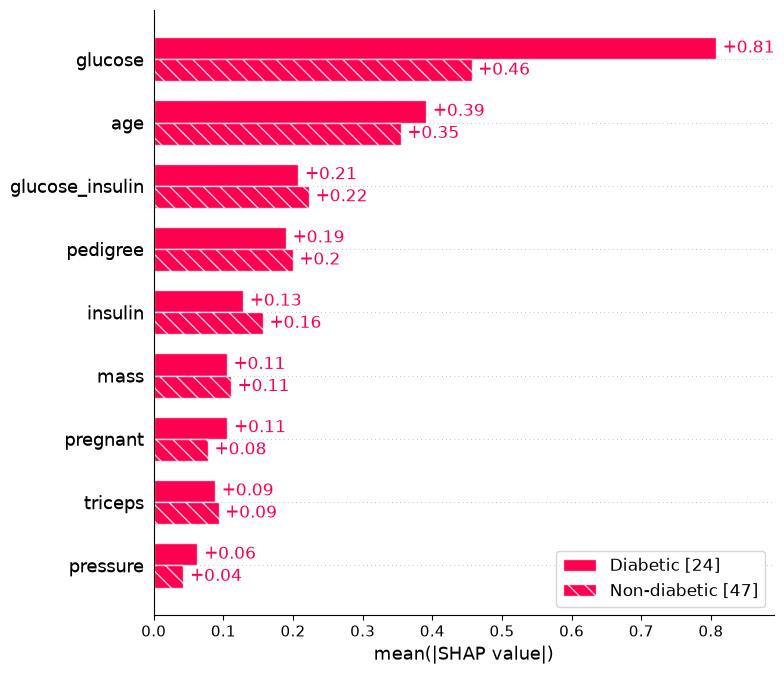

In [25]:
shap.plots.bar(cohort_values.abs.mean(0))

<div style="border: 3px dashed white; padding: 10px; box-sizing: border-box;">

<i>

<h3>Observations</h3>

* Looks like there is now an even bigger gap between the cohorts with `Diabetic` and `Non-diabetic`.

* The other features seemed to have evened out

</div>

### <i> beeswarm

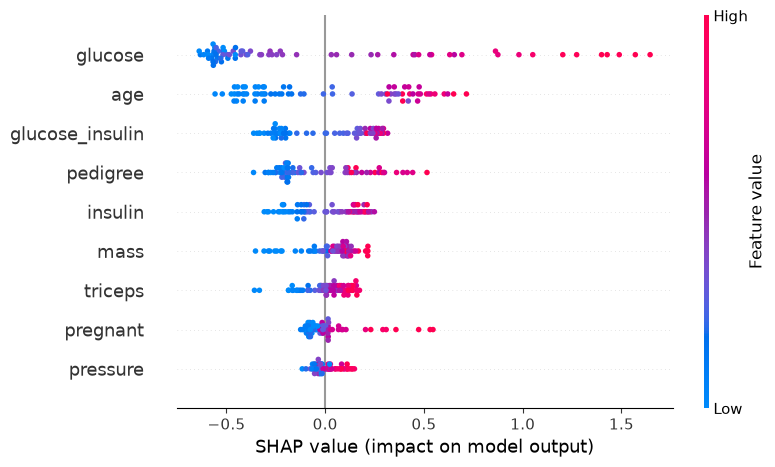

In [26]:
shap.plots.beeswarm(shap_values)

<div style="border: 3px dashed white; padding: 10px; box-sizing: border-box;">

<h3>Observations</h3>

* All non `glucose` features seemed to have less variance in their shapley values. 

* We can clearly see some importance clusters in `mass` `insulin`. That's a very good sign.

</div>

### <i> Decision plots (isolated worst cases)

In [27]:
# Get the prediction error.
residuals = y_test - y_pred

# Create a copy of the test dataframe
predictions_df = X_test.copy()

# Add actual and predicted values
predictions_df["Actual"] = y_test
predictions_df["Predicted"] = y_pred

# Add residuals
predictions_df["Residual"] = residuals

# Sort by the worst predictions
worst_predictions = predictions_df.sort_values("Residual", ascending=False)
worst_predictions

,pregnant,glucose,pressure,triceps,insulin,mass,pedigree,age,glucose_insulin,Actual,Predicted,Residual
60,1,117,88,24,145,34.5,0.403,40,16965,1,0,1
164,2,102,86,36,120,45.5,0.127,23,12240,1,0,1
146,14,100,78,25,184,36.6,0.412,46,18400,1,0,1
49,0,95,85,25,36,37.4,0.247,24,3420,1,0,1
325,7,97,76,32,91,40.9,0.871,32,8827,1,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...
310,1,181,78,42,293,40.0,1.258,22,53033,1,1,0
9,3,126,88,41,235,39.3,0.704,27,29610,0,0,0
255,6,154,74,32,193,29.3,0.839,39,29722,0,1,-1
134,7,136,74,26,135,26.0,0.647,51,18360,0,1,-1


In [28]:
# Find the index position in X_test from worst_predictions 
row_position = X_test.index.get_loc(202)
print(f"The shap_value index is: {row_position}")

The shap_value index is: 61


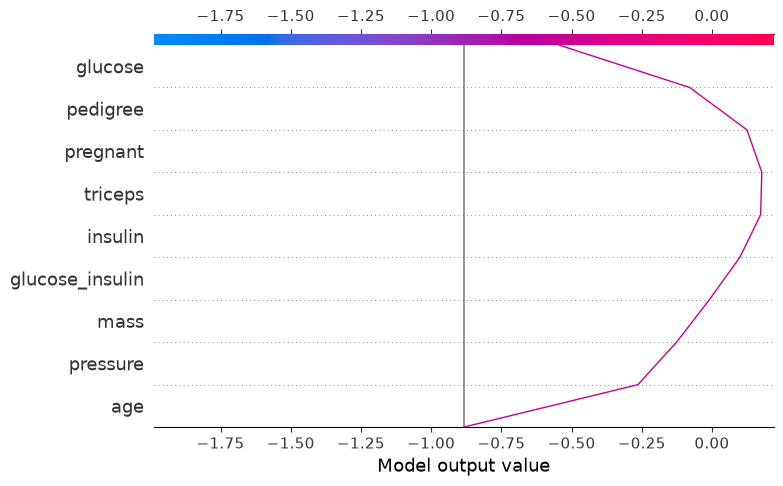

In [29]:
# Decision plot
shap.decision_plot(
    shap_values.base_values[0],
    shap_values.values[0],
    feature_names=X_test.columns.tolist(),
    feature_order="hclust",
    show=True
)

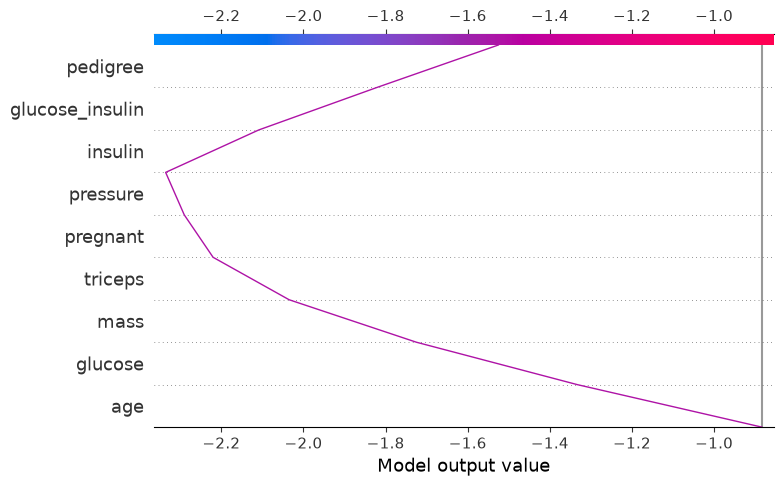

In [30]:
# Decision plot
shap.decision_plot(
    shap_values.base_values[12],
    shap_values.values[12],
    feature_names=X_test.columns.tolist(),
    feature_order="hclust",
    show=True
)

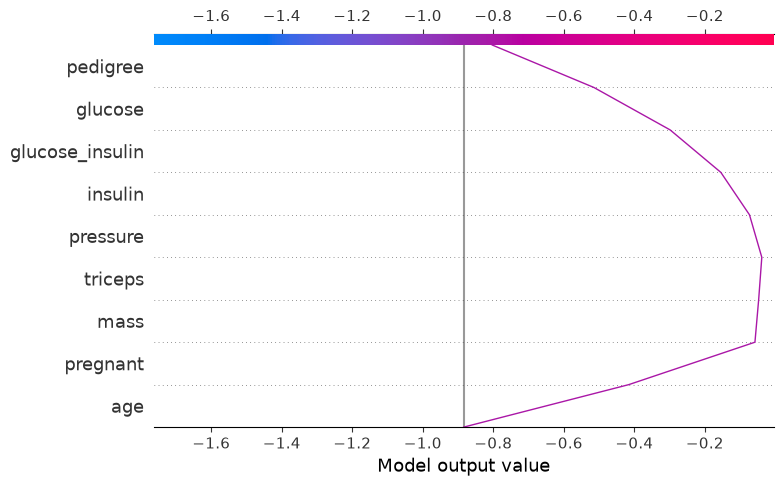

In [31]:
# Decision plot
shap.decision_plot(
    shap_values.base_values[14],
    shap_values.values[14],
    feature_names=X_test.columns.tolist(),
    feature_order="hclust",
    show=True
)

<div style="border: 3px dashed white; padding: 10px; box-sizing: border-box;">

<i>

<h3>Observations</h3>

It appears that `age` is the primary contributor every time for residual errors. We could maybe consider for next time to scale values or checking for multicollinearity!


</div>